# Extra figures

Supporting figures from the answer summary, loaded from compact saved data.
The first figure measures zero-field thermal decorrelation at 300 K and
compares its timescale with zero-field endpoint observables. Raw simulation
trajectories and an external drive are not needed to run this notebook.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

%matplotlib inline

In [2]:
plt.rcParams.update({
    "pgf.texsystem": "pdflatex",
    'font.family': 'serif',
    'text.usetex': True,
    'pgf.rcfonts': False,
    'xtick.labelsize':11,
    'ytick.labelsize':11,
    'axes.labelsize':11,
})

In [3]:
REPO = Path.cwd().resolve()
while not (REPO / 'src' / 'notebooks').is_dir():
    REPO = REPO.parent
FIGURE_DIR = REPO / 'data' / 'figures' / 'paper' / 'extra'
DATA = FIGURE_DIR


## Zero-field autocorrelation and thermal timescale

The observable is signed well occupancy along each particle's initial trap
axis. Its correlation is centered using the symmetric zero-field equilibrium
mean of zero. The saved analysis uses ten 1000 s realizations at 300 K, 200
particles per realization, and a 0.05 s saved interval. We use the 200 s burn-in
result and the exponential fit over lags 1–300 s.

The decay time is **104.2 ± 1.5 s**, with the uncertainty equal to the sample
standard deviation of 500 bootstrap resamples of independent realizations.
The associated angular frequency is **0.01507 ± 0.00021 rad/s**, defined by
omega_T = pi/(2 tau_T). This decay time is not a first-passage time; in the
symmetric stationary two-state model, the mean residence time is twice the
correlation decay time.

The left band shows ±1 SEM of the correlation across realizations. The right
panel retains the summary comparison with normalized charge order and ice-rule
defects at B=0, with endpoint SEMs. Its shaded frequency band uses the saved
bootstrap interval, rather than ±1 SE. Source paths and hashes are recorded
in `data_provenance.json`; method metadata are retained beside the CSVs.

In [4]:
correlation = pd.read_csv(DATA / 'zero_field_correlations.csv')
correlation_times = pd.read_csv(DATA / 'zero_field_correlation_times.csv')
zero = pd.read_csv(DATA / 'zero_field_endpoints.csv')
bootstrap = pd.read_csv(DATA / 'zero_field_correlation_bootstrap.csv')
tau_se = bootstrap.tau_exp_s.std(ddof=1)
omega_se = bootstrap.omega_rad_s.std(ddof=1)
thermal = correlation_times.query('burn_in_s == 200').iloc[0]
assert len(bootstrap) == 500 and zero.n.eq(10).all()
assert np.isfinite(correlation[['C', 'C_sem']]).all().all()
display(pd.DataFrame({
    'quantity': ['tau_T [s]', 'omega_T [rad/s]'],
    'estimate': [thermal.tau_exp_s, thermal.omega_from_tau_rad_s],
    'bootstrap_SE': [tau_se, omega_se]}))

,quantity,estimate,bootstrap_SE
0,tau_T [s],104.247985,1.455221
1,omega_T [rad/s],0.015068,0.000210


## Autocorrelation figure

This reproduces the two-panel supporting figure from the summary. The fitted
time and its bootstrap uncertainty are included in the left legend.

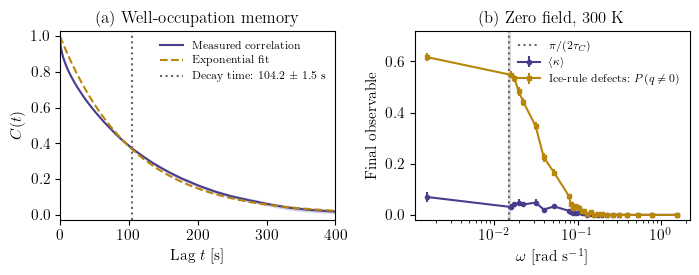

In [5]:
def plot_zero_field_correlation(correlation, times, endpoints, burn=200):
    r = times.query("burn_in_s == @burn").iloc[0]
    c = correlation.query("burn_in_s == @burn")
    fig, ax = plt.subplots(1, 2, figsize=(7.1, 2.85))
    ax[0].plot(c.lag_s, c.C, color="darkslateblue", label="Measured correlation")
    ax[0].fill_between(c.lag_s, c.C-c.C_sem, c.C+c.C_sem, color="darkslateblue", alpha=.15)
    ax[0].plot(c.lag_s, np.exp(-c.lag_s/r.tau_exp_s), color="darkgoldenrod", ls="--", label="Exponential fit")
    ax[0].axvline(r.tau_exp_s, color=".4", ls=":",
                   label=f"Decay time: {r.tau_exp_s:.1f} ± {tau_se:.1f} s")
    ax[0].set(xlim=(0, 400), ylim=(-.03, 1.03), xlabel=r"Lag $t$ [s]", ylabel=r"$C(t)$", title="(a) Well-occupation memory")
    ax[0].legend(frameon=False, fontsize=8)
    z = endpoints.sort_values("omega")
    ax[1].errorbar(z.omega, z.kappa, yerr=z.kappa_sem, color="darkslateblue", marker="o", ms=3,
                   label=r"$\langle\kappa\rangle$")
    ax[1].errorbar(z.omega, z.defect_fraction, yerr=z.defect_sem, color="darkgoldenrod", marker="s", ms=3,
                   label=r"Ice-rule defects: $P(q\ne0)$")
    ax[1].axvspan(r.omega_lower_rad_s, r.omega_upper_rad_s, color=".5", alpha=.18)
    ax[1].axvline(r.omega_from_tau_rad_s, color=".4", ls=":", label=r"$\pi/(2\tau_C)$")
    ax[1].set(xscale="log", xlabel=r"$\omega$ [rad s$^{-1}$]", ylabel="Final observable", title="(b) Zero field, 300 K", ylim=(-.02, .72))
    ax[1].legend(frameon=False, fontsize=8, loc="upper right")
    fig.tight_layout(w_pad=1.4)
    return fig
fig = plot_zero_field_correlation(correlation, correlation_times, zero)
for suffix in ['pdf', 'png']:
    fig.savefig(FIGURE_DIR / f'zero_field_correlation_and_ordering.{suffix}',
                dpi=300, bbox_inches='tight')
plt.show()

## Exports

PDF and PNG are saved beside the local source tables. Additional supporting
figures can be added below as needed.

In [6]:
exports = [FIGURE_DIR / f'zero_field_correlation_and_ordering.{suffix}'
           for suffix in ['pdf', 'png']]
display(pd.DataFrame({'file': [str(p.relative_to(REPO)) for p in exports],
                      'bytes': [p.stat().st_size for p in exports]}))

,file,bytes
0,data/figures/paper/extra/zero_field_correlatio...,610131
1,data/figures/paper/extra/zero_field_correlatio...,128258
